# 01 - Exploratory Analysis & Problem Framing
### Day-ahead forecasting of French hourly electricity demand

**Business context.** Our utility buys electricity on the day-ahead market. Every day **D**, before the auction
closes at **12:00 CET**, the trading desk must know the demand for every hour of day **D+1**. Each MWh of forecast
error is settled later at imbalance prices, and the **evening peaks of cold days** are where errors cost the most.

This notebook analyses the **cleaned national series produced by Notebook 00**. It does the decisive analytical
work: understand the demand, prove its structure with statistics, and frame the problem the modelling notebooks
will tackle.

**What this notebook delivers**
1. A visual + statistical tour of the demand: distribution, multi-scale seasonality, trend.
2. **Statistical tests** backing every claim: stationarity (ADF / KPSS), autocorrelation (Ljung-Box),
   temperature dependence (Pearson / Spearman), and a significance test on the RTE bias.
3. An audit of **RTE's own day-ahead forecast** - the benchmark we must beat - to find *where* it fails.
4. A look at the fixed, chronological **train / validation / test split** used by the modelling notebooks.

> **Data note.** Loading, structural validation and cleaning (incl. the DST-gap imputation) live in
> **Notebook 00**, which also prepares the regional data. Here we load its cleaned output and focus on analysis.

> **Honesty rule for the whole project.** On day D at 12:00 CET we may only use information available at that
> moment. This notebook builds no forecasting features yet, but the split and the RTE audit are designed around
> that rule so Notebooks 2 and 3 inherit a fair playing field.

## 0 - Setup
Libraries, a single consistent visual style, and the data path.

In [1]:
import warnings
warnings.filterwarnings("ignore")  # keep the narrative clean; every statistical test is reported explicitly

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox

pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
print("Ready - pandas", pd.__version__, "| numpy", np.__version__)

Ready - pandas 3.0.6 | numpy 2.5.2


In [2]:
# ---- One colourblind-safe visual system for every chart (brand-neutral, validated palette) ----
PALETTE = {
    "blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "yellow": "#eda100",
    "violet": "#6250d6", "red": "#e34948", "green": "#0ca30c",
    "ink": "#0b0b0b", "ink2": "#52514e", "muted": "#898781",
    "grid": "#e1e0d9", "surface": "#fcfcfb",
}
BLUE_RAMP = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
BLUE_CMAP = LinearSegmentedColormap.from_list("brand_blue", BLUE_RAMP)
DIVERGING = LinearSegmentedColormap.from_list(
    "brand_div", ["#184f95", "#86b6ef", "#f0efec", "#eb8f8f", "#c0201f"])

plt.rcParams.update({
    "figure.facecolor": PALETTE["surface"], "axes.facecolor": PALETTE["surface"],
    "savefig.facecolor": PALETTE["surface"], "savefig.bbox": "tight",
    "axes.edgecolor": PALETTE["muted"], "axes.linewidth": 0.8,
    "axes.labelcolor": PALETTE["ink2"], "axes.titlecolor": PALETTE["ink"],
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlepad": 10, "axes.labelsize": 11,
    "text.color": PALETTE["ink"], "xtick.color": PALETTE["muted"], "ytick.color": PALETTE["muted"],
    "xtick.labelcolor": PALETTE["ink2"], "ytick.labelcolor": PALETTE["ink2"],
    "axes.grid": True, "grid.color": PALETTE["grid"], "grid.linewidth": 0.8, "grid.alpha": 0.9,
    "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 11, "legend.frameon": False, "legend.fontsize": 10,
    "figure.dpi": 110, "figure.titlesize": 14, "figure.titleweight": "bold", "lines.linewidth": 1.8,
})

gw_fmt  = FuncFormatter(lambda v, _: f"{v/1000:,.0f}")  # MW -> GW (whole GW, for 30-90 GW scales)
gw1_fmt = FuncFormatter(lambda v, _: f"{v/1000:,.1f}")  # MW -> GW (1 decimal, for ~1 GW error scales)

def titled(ax, title=None, xlabel=None, ylabel=None):
    # consistent left-aligned title + labels
    if title is not None: ax.set_title(title, loc="left")
    if xlabel is not None: ax.set_xlabel(xlabel)
    if ylabel is not None: ax.set_ylabel(ylabel)
    ax.margins(x=0.01)
    return ax

FIG = Path("..") / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
print("Visual style loaded.")

Visual style loaded.


## 1 - Load the cleaned dataset (from Notebook 00)
We start from the analysis-ready national series: cleaned, enriched with calendar features, and labelled with the train/val/test split.

In [3]:
PROC = Path("..") / "data" / "processed" / "france_clean_hourly.csv"
df = pd.read_csv(PROC)
df["datetime_utc"] = pd.to_datetime(df["datetime_utc"], utc=True)   # restore the tz-aware UTC index from CSV
df = df.set_index("datetime_utc")

print(f"Rows   : {len(df):,}")
print(f"Span   : {df.index.min()}  ->  {df.index.max()}   (tz = {df.index.tz})")
print(f"Columns: {list(df.columns)}")
df.head()

Rows   : 65,712
Span   : 2019-01-01 00:00:00+00:00  ->  2026-06-30 23:00:00+00:00   (tz = UTC)
Columns: ['load_mw', 'rte_forecast_d1_mw', 'temperature_c', 'hour', 'dow', 'month', 'year', 'is_weekend', 'is_holiday', 'season', 'split']


,load_mw,rte_forecast_d1_mw,temperature_c,hour,dow,month,year,is_weekend,is_holiday,season,split
datetime_utc,,,,,,,,,,,
2019-01-01 00:00:00+00:00,"60,826.000","60,837.500",5.850,1,1,1,2019,False,True,Winter,train
2019-01-01 01:00:00+00:00,"59,786.500","59,500.000",6.350,2,1,1,2019,False,True,Winter,train
2019-01-01 02:00:00+00:00,"56,622.000","56,012.500",5.910,3,1,1,2019,False,True,Winter,train
2019-01-01 03:00:00+00:00,"53,919.500","53,300.000",5.700,4,1,1,2019,False,True,Winter,train
2019-01-01 04:00:00+00:00,"52,972.000","52,187.500",5.720,5,1,1,2019,False,True,Winter,train


**Columns.** `load_mw` is our target (actual French consumption); `rte_forecast_d1_mw` is the day-ahead
forecast published by **RTE** (*Reseau de Transport d'Electricite*, France's electricity transmission system
operator / national grid manager) - its official open-data demand forecast and **the benchmark we must beat**;
`temperature_c` is the dominant weather driver. The calendar
features (`hour`, `dow`, `month`, `year`, `is_weekend`, `is_holiday`, `season`) and the `split` label were all
produced by **Notebook 00**. The index is tz-aware **UTC** (no DST ambiguity); calendar fields were derived in
Paris local time. Cleaning recap: the only issue was **7 missing values (0.011%)**, all at the autumn DST change,
imputed by time interpolation - full detail in Notebook 00.

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
load_mw,"65,712.000","51,501.494","11,016.376","29,364.500","43,332.500","49,777.500","58,745.750","90,233.500"
rte_forecast_d1_mw,"65,712.000","50,830.028","11,048.272","27,712.500","42,587.500","48,962.500","58,062.500","89,975.000"
temperature_c,"65,712.000",13.072,7.023,-5.090,7.920,12.500,17.980,38.520
hour,"65,712.000",11.500,6.922,0.000,5.750,11.500,17.250,23.000
dow,"65,712.000",2.999,2.000,0.000,1.000,3.000,5.000,6.000
month,"65,712.000",6.324,3.444,1.000,3.000,6.000,9.000,12.000
year,"65,712.000","2,022.265",2.173,"2,019.000","2,020.000","2,022.000","2,024.000","2,026.000"


## 2 - The demand series at a glance
Seven and a half years of hourly load, shown as a daily mean so the structure is legible.

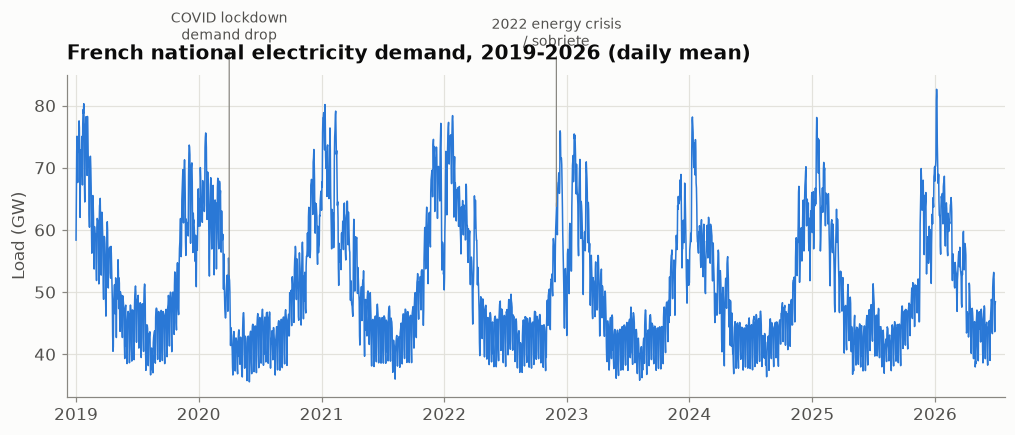

In [5]:
daily = df["load_mw"].resample("D").mean()

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(daily.index, daily.values, color=PALETTE["blue"], lw=1.0)
ax.yaxis.set_major_formatter(gw_fmt)

# annotate two real regime effects (NOT data errors - we must keep them)
for when, text, dy in [("2020-04-01", "COVID lockdown\ndemand drop", 8),
                       ("2022-12-01", "2022 energy crisis\n/ sobriete", 7)]:
    x = pd.Timestamp(when, tz="UTC")
    ax.annotate(text, xy=(x, daily.loc[:x].iloc[-1]), xytext=(x, daily.max() + dy * 1000),
                color=PALETTE["ink2"], fontsize=9, ha="center",
                arrowprops=dict(arrowstyle="-", color=PALETTE["muted"], lw=0.8))
titled(ax, "French national electricity demand, 2019-2026 (daily mean)",
       xlabel="", ylabel="Load (GW)")
fig.savefig(FIG / "02_overview.png")
plt.show()

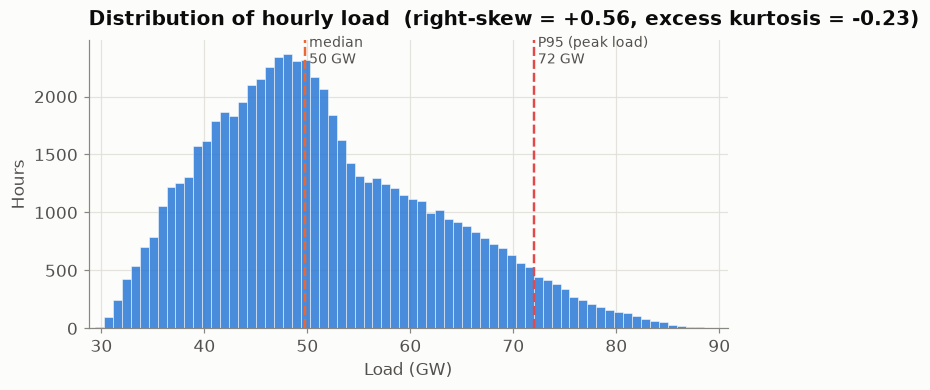

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.hist(df["load_mw"], bins=70, color=PALETTE["blue"], alpha=0.85, edgecolor=PALETTE["surface"], linewidth=0.4)
for q, lab in [(0.5, "median"), (0.95, "P95 (peak load)")]:
    v = df["load_mw"].quantile(q)
    ax.axvline(v, color=PALETTE["orange"] if q == 0.5 else PALETTE["red"], lw=1.6, ls="--")
    ax.text(v, ax.get_ylim()[1]*0.92, f" {lab}\n {v/1000:,.0f} GW", color=PALETTE["ink2"], fontsize=9)
ax.xaxis.set_major_formatter(gw_fmt)
sk, ku = stats.skew(df["load_mw"]), stats.kurtosis(df["load_mw"])
titled(ax, f"Distribution of hourly load  (right-skew = {sk:+.2f}, excess kurtosis = {ku:+.2f})",
       xlabel="Load (GW)", ylabel="Hours")
fig.savefig(FIG / "03_distribution.png")
plt.show()

The distribution is **right-skewed**: most hours sit near the median (~50 GW) but a long upper tail reaches
~90 GW. That tail is the **cold-snap evening peak** - rare hours, but exactly where imbalance costs concentrate.
A good forecaster must earn its keep in that tail, not just on average.

## 3 - Multi-scale seasonality
Electricity demand is driven by human routines and weather, producing three nested cycles: daily, weekly, yearly.

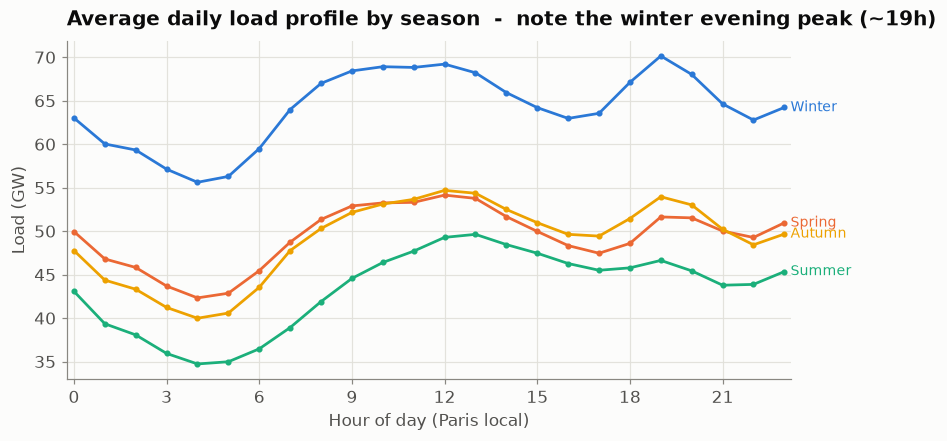

In [7]:
# 5a - Average daily shape by season (hour of day, local time)
prof = df.groupby(["season", "hour"])["load_mw"].mean().unstack(0)
order  = ["Winter", "Spring", "Summer", "Autumn"]
colors = {"Winter": PALETTE["blue"], "Spring": PALETTE["orange"],
          "Summer": PALETTE["aqua"], "Autumn": PALETTE["yellow"]}

fig, ax = plt.subplots(figsize=(8.5, 4))
for s in order:
    ax.plot(prof.index, prof[s], color=colors[s], label=s, marker="o", ms=3)
    ax.text(23.2, prof[s].iloc[-1], s, color=colors[s], fontsize=9, va="center")  # direct labels
ax.yaxis.set_major_formatter(gw_fmt)
ax.set_xticks(range(0, 24, 3))
titled(ax, "Average daily load profile by season  -  note the winter evening peak (~19h)",
       xlabel="Hour of day (Paris local)", ylabel="Load (GW)")
fig.savefig(FIG / "04_daily_profile.png")
plt.show()

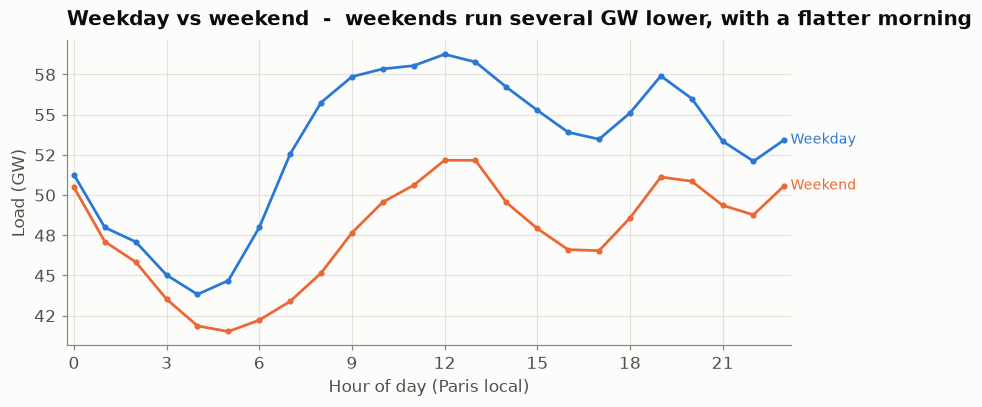

In [8]:
# 5b - Weekday vs weekend daily shape
wk = (df.assign(kind=np.where(df["is_weekend"], "Weekend", "Weekday"))
        .groupby(["kind", "hour"])["load_mw"].mean().unstack(0))
fig, ax = plt.subplots(figsize=(8.5, 3.6))
for kind, c in [("Weekday", PALETTE["blue"]), ("Weekend", PALETTE["orange"])]:
    ax.plot(wk.index, wk[kind], color=c, marker="o", ms=3, label=kind)
    ax.text(23.2, wk[kind].iloc[-1], kind, color=c, fontsize=9, va="center")
ax.yaxis.set_major_formatter(gw_fmt)
ax.set_xticks(range(0, 24, 3))
titled(ax, "Weekday vs weekend  -  weekends run several GW lower, with a flatter morning",
       xlabel="Hour of day (Paris local)", ylabel="Load (GW)")
fig.savefig(FIG / "05_weekday_weekend.png")
plt.show()

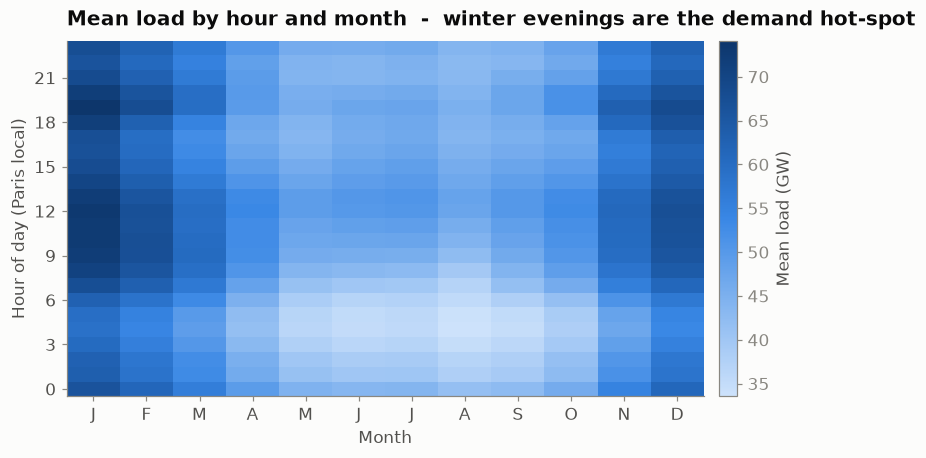

In [9]:
# 5c - Hour x Month heatmap (the whole seasonal story in one panel)
hm = df.groupby(["hour", "month"])["load_mw"].mean().unstack("month") / 1000  # GW
fig, ax = plt.subplots(figsize=(9, 4.2))
im = ax.imshow(hm.values, aspect="auto", origin="lower", cmap=BLUE_CMAP)
ax.set_xticks(range(12)); ax.set_xticklabels(["J","F","M","A","M","J","J","A","S","O","N","D"])
ax.set_yticks(range(0, 24, 3)); ax.set_yticklabels(range(0, 24, 3))
ax.grid(False)
cb = fig.colorbar(im, ax=ax, pad=0.02); cb.set_label("Mean load (GW)", color=PALETTE["ink2"])
cb.ax.tick_params(colors=PALETTE["muted"])
titled(ax, "Mean load by hour and month  -  winter evenings are the demand hot-spot",
       xlabel="Month", ylabel="Hour of day (Paris local)")
fig.savefig(FIG / "06_hour_month_heatmap.png")
plt.show()

**Three cycles, one picture.** The heatmap concentrates the story: demand peaks in **winter evenings**
(top-left / top-right corners) and troughs on **summer nights**. The daily profile shows the morning ramp and the
sharp **~19h winter peak**; weekends sit several GW below weekdays. These are the cycles any model must capture -
and they motivate the seasonal terms (daily = 24h, weekly = 168h) we test next.

### Regional variation around the national pattern
The 12 regions (cleaned in Notebook 00) share France's rhythm but not identically. Overlaid on one plot - each
region's daily profile indexed to its own mean (so *shape*, not size, is compared) and coloured by climate - the
**spread around the national mean** shows which regions are peakier or flatter.

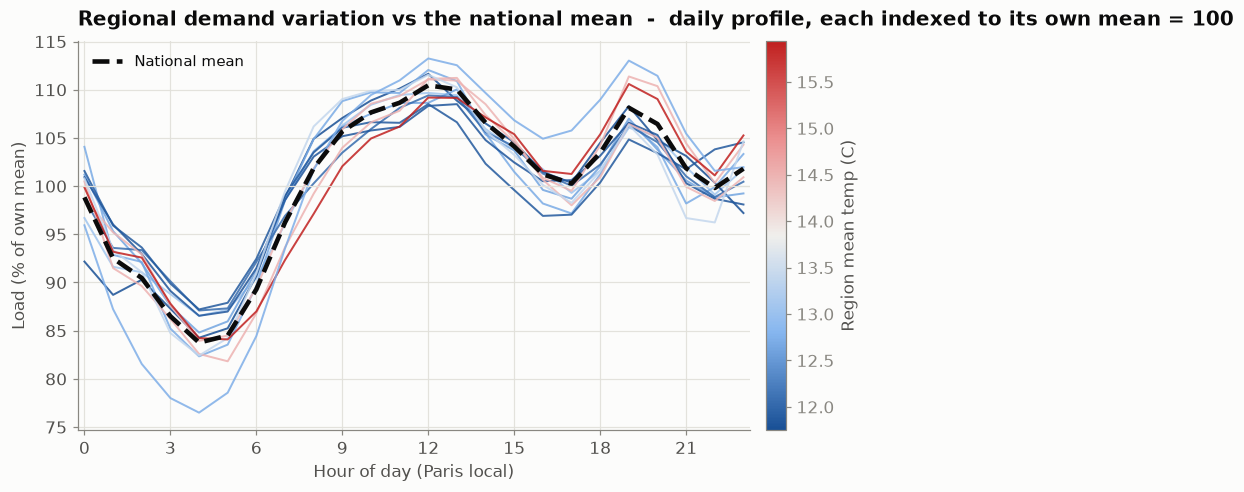

In [10]:
# Regional demand variation vs national (uses the regional file prepared in Notebook 00)
regn = pd.read_csv(Path("..") / "data" / "processed" / "france_regional_clean_hourly.csv")

# average daily profile per region, each indexed to its OWN mean = 100 (compare shape, not size)
rp = regn.groupby(["region", "hour"])["load_mw"].mean()
rp_idx = (rp / rp.groupby("region").transform("mean") * 100).unstack("region")     # rows = hour, cols = region
# national profile on the SAME window (regions begin 2023), indexed to its own mean
natw = df.loc["2023-01-01":]
nat_idx = natw.groupby("hour")["load_mw"].mean(); nat_idx = nat_idx / nat_idx.mean() * 100
# colour each region by its mean temperature so the spread carries meaning
rtemp = regn.groupby("region")["temperature_c"].mean(); nrm = plt.Normalize(rtemp.min(), rtemp.max())

fig, ax = plt.subplots(figsize=(9.5, 4.6))
for rg in rp_idx.columns:
    ax.plot(rp_idx.index, rp_idx[rg].values, color=DIVERGING(nrm(rtemp[rg])), lw=1.3, alpha=0.85)
ax.plot(nat_idx.index, nat_idx.values, color=PALETTE["ink"], lw=3.0, ls="--", label="National mean", zorder=6)
ax.axhline(100, color=PALETTE["grid"], lw=0.8); ax.set_xticks(range(0, 24, 3))
sm = plt.cm.ScalarMappable(cmap=DIVERGING, norm=nrm); sm.set_array([])
cb = fig.colorbar(sm, ax=ax, pad=0.02); cb.set_label("Region mean temp (C)", color=PALETTE["ink2"]); cb.ax.tick_params(colors=PALETTE["muted"])
ax.legend(loc="upper left")
titled(ax, "Regional demand variation vs the national mean  -  daily profile, each indexed to its own mean = 100",
       xlabel="Hour of day (Paris local)", ylabel="Load (% of own mean)")
fig.savefig(FIG / "16_regional_variation.png"); plt.show()

**Regional spread.** Regions spread several points around the national mean - some run a **steeper evening
peak and a deeper night trough** than France as a whole (the dense-urban regions vary most), others are flatter.
The colouring shows this is **not** a clean cold-vs-warm split. A single national model averages the spread away; a
per-region bottom-up model can exploit it (the hierarchical angle used later).

## 4 - Decomposition & stationarity (statistical backing)
We separate trend / seasonal / remainder with STL, then test stationarity formally with ADF and KPSS.

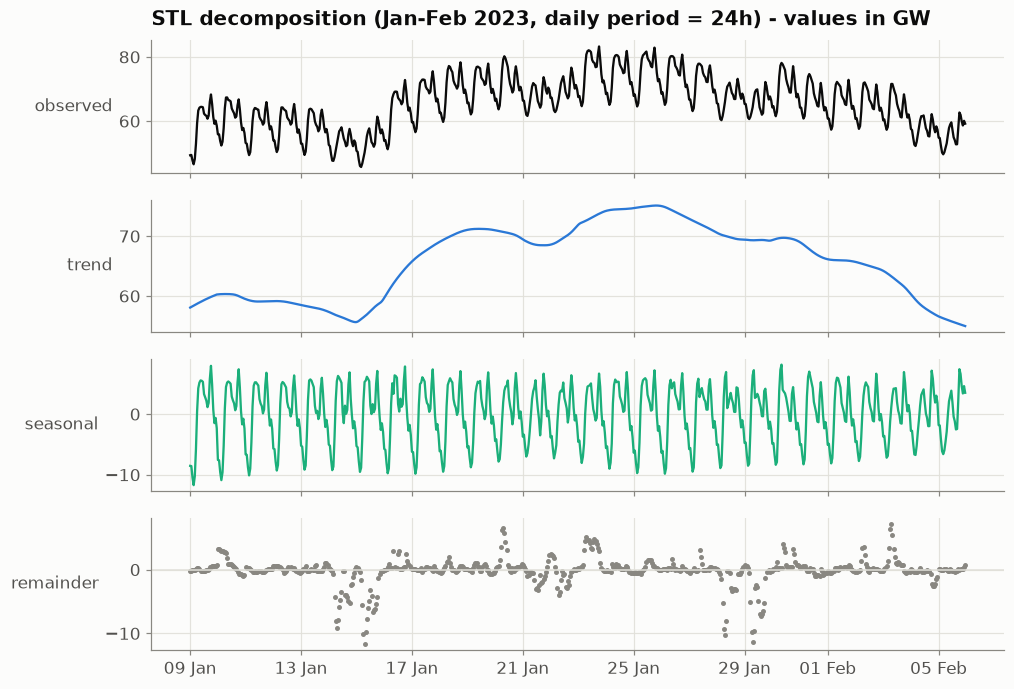

In [11]:
# STL on a readable 4-week window (period = 24h) to visualise the daily cycle + slow trend
stl_win = df.loc["2023-01-09":"2023-02-05", "load_mw"]
res = STL(stl_win, period=24, robust=True).fit()
comp = pd.DataFrame({"observed": res.observed, "trend": res.trend,
                     "seasonal": res.seasonal, "remainder": res.resid})

fig, axes = plt.subplots(4, 1, figsize=(10, 7.2), sharex=True)
parts = [("observed", PALETTE["ink"]), ("trend", PALETTE["blue"]),
         ("seasonal", PALETTE["aqua"]), ("remainder", PALETTE["muted"])]
for ax, (col, c) in zip(axes, parts):
    if col == "remainder":
        ax.axhline(0, color=PALETTE["grid"], lw=1)
        ax.scatter(comp.index, comp[col] / 1000, s=5, color=c)
    else:
        ax.plot(comp.index, comp[col] / 1000, color=c, lw=1.5)
    ax.set_ylabel(col, rotation=0, ha="right", va="center", color=PALETTE["ink2"])
axes[0].set_title("STL decomposition (Jan-Feb 2023, daily period = 24h) - values in GW", loc="left")
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
fig.savefig(FIG / "07_stl.png")
plt.show()

In [12]:
# Stationarity tests. ADF H0 = has a unit root (non-stationary). KPSS H0 = stationary.
def stationarity(series, name):
    s = pd.Series(series).dropna()
    if len(s) > 20000:                       # ADF autolag is costly; a 3-year slice is representative
        s = s.iloc[-20000:]
    adf = adfuller(s, autolag="AIC")
    kp  = kpss(s, regression="c", nlags="auto")
    return {
        "series": name,
        "ADF stat": round(adf[0], 2), "ADF p": round(adf[1], 4),
        "ADF -> ": "stationary" if adf[1] < 0.05 else "unit root",
        "KPSS stat": round(kp[0], 3), "KPSS p": round(kp[1], 4),
        "KPSS -> ": "stationary" if kp[1] > 0.05 else "non-stationary",
    }

load = df["load_mw"]
stat_tbl = pd.DataFrame([
    stationarity(load,                      "load (raw)"),
    stationarity(load.diff(1),              "diff-1 (hourly)"),
    stationarity(load.diff(24),             "diff-24 (seasonal)"),
    stationarity(load.diff(24).diff(1),     "diff-24 then diff-1"),
])
stat_tbl

C:\Users\marouane.housni\AppData\Local\Temp\ipykernel_30964\1017054417.py:7: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kp  = kpss(s, regression="c", nlags="auto")


C:\Users\marouane.housni\AppData\Local\Temp\ipykernel_30964\1017054417.py:7: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kp  = kpss(s, regression="c", nlags="auto")


C:\Users\marouane.housni\AppData\Local\Temp\ipykernel_30964\1017054417.py:7: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kp  = kpss(s, regression="c", nlags="auto")


C:\Users\marouane.housni\AppData\Local\Temp\ipykernel_30964\1017054417.py:7: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kp  = kpss(s, regression="c", nlags="auto")


,series,ADF stat,ADF p,ADF ->,KPSS stat,KPSS p,KPSS ->
0,load (raw),-5.490,0.000,stationary,1.675,0.010,non-stationary
1,diff-1 (hourly),-22.630,0.000,stationary,0.042,0.100,stationary
2,diff-24 (seasonal),-23.400,0.000,stationary,0.012,0.100,stationary
3,diff-24 then diff-1,-33.610,0.000,stationary,0.001,0.100,stationary


**How to read this.** The two tests have *opposite* null hypotheses, so agreement is informative. On the
**raw** series ADF often rejects a unit root (strong periodic mean-reversion looks "stationary"), yet **KPSS
rejects stationarity** because of the slow trend and seasonal mean shifts - the classic signature of a series that
needs differencing. After **seasonal differencing (lag 24)** - optionally combined with a first difference - both
tests agree the series is stationary. This is the empirical justification for the **seasonal (S)ARIMA** orders we
calibrate in Notebook 2.

### ACF and PACF in detail
Shown as **two separate, wide plots** on the stationary seasonal difference (lag-24). The trivial lag-0 spike is
removed (`zero=False`) and the y-axis auto-zooms, so the real variation is visible; dotted lines mark **daily
multiples (24, 48, ... 168h)** and the shaded band is the 95% significance interval - anything outside it is real
structure.

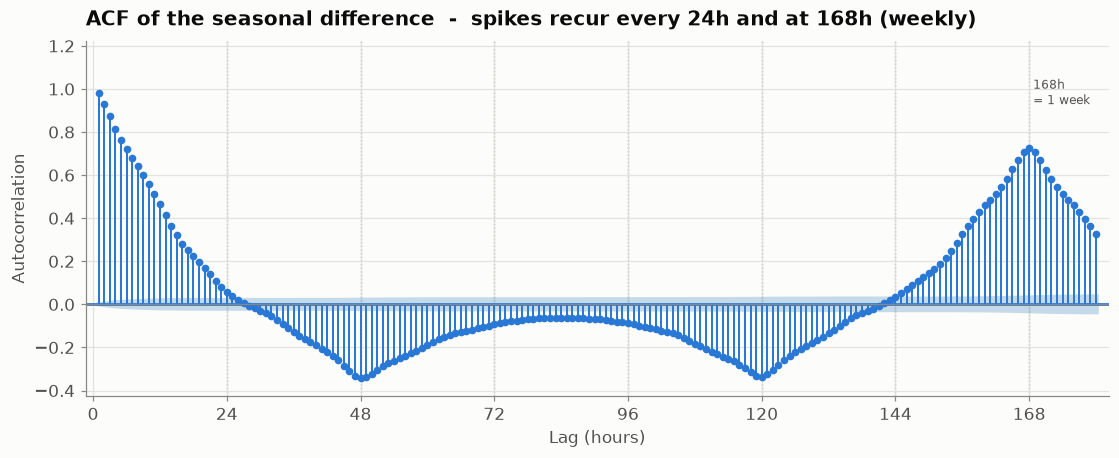

In [13]:
# Stationary series to read the orders from: the seasonal (lag-24) difference
d = df["load_mw"].diff(24).dropna()
daily_lags = [24, 48, 72, 96, 120, 144, 168]

# ---- ACF (up to 180h = 7.5 days, so the weekly echo at 168h is visible) ----
fig, ax = plt.subplots(figsize=(12, 4.2))
plot_acf(d, lags=180, ax=ax, zero=False, auto_ylims=True, alpha=0.05, title=None,
         color=PALETTE["blue"], markersize=4, vlines_kwargs={"colors": PALETTE["blue"], "linewidth": 1.3})
for L in daily_lags:
    ax.axvline(L, color=PALETTE["muted"], ls=":", lw=0.9, zorder=0)
ax.text(168, ax.get_ylim()[1] * 0.86, " 168h\n = 1 week", color=PALETTE["ink2"], fontsize=8, va="top")
ax.axhline(0, color=PALETTE["muted"], lw=0.8)
ax.set_xticks(range(0, 181, 24)); ax.grid(axis="y", color=PALETTE["grid"], lw=0.8)
titled(ax, "ACF of the seasonal difference  -  spikes recur every 24h and at 168h (weekly)",
       xlabel="Lag (hours)", ylabel="Autocorrelation")
fig.savefig(FIG / "08_acf.png")
plt.show()

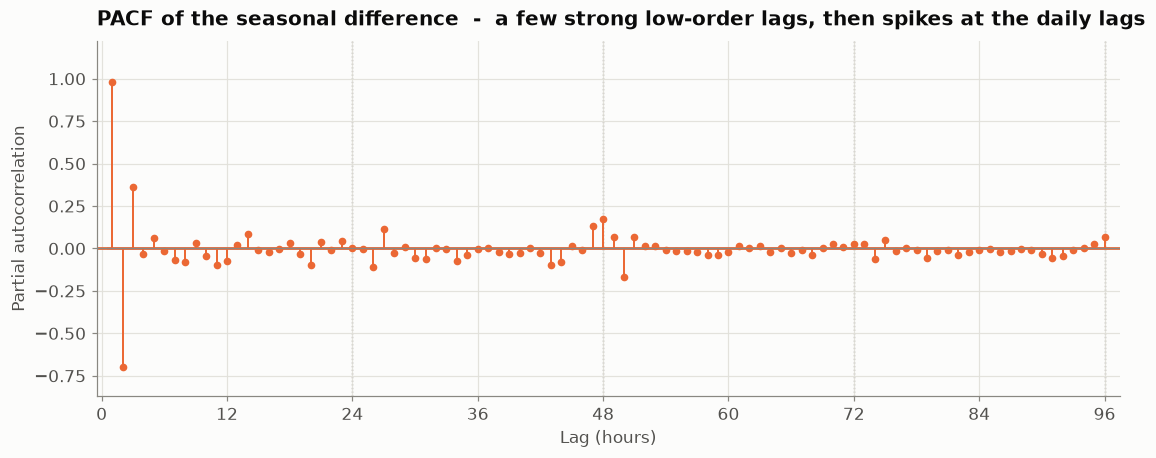

In [14]:
# ---- PACF (up to 96h = 4 days; beyond that the PACF gets noisy) ----
fig, ax = plt.subplots(figsize=(12, 4.2))
plot_pacf(d, lags=96, ax=ax, zero=False, auto_ylims=True, alpha=0.05, method="ywm", title=None,
          color=PALETTE["orange"], markersize=4, vlines_kwargs={"colors": PALETTE["orange"], "linewidth": 1.3})
for L in [24, 48, 72, 96]:
    ax.axvline(L, color=PALETTE["muted"], ls=":", lw=0.9, zorder=0)
ax.axhline(0, color=PALETTE["muted"], lw=0.8)
ax.set_xticks(range(0, 97, 12)); ax.grid(axis="y", color=PALETTE["grid"], lw=0.8)
titled(ax, "PACF of the seasonal difference  -  a few strong low-order lags, then spikes at the daily lags",
       xlabel="Lag (hours)", ylabel="Partial autocorrelation")
fig.savefig(FIG / "08_pacf.png")
plt.show()

In [15]:
# Ljung-Box: is there autocorrelation to exploit? (tiny p = yes, strongly)
lb = acorr_ljungbox(df["load_mw"], lags=[1, 24, 168], return_df=True)
lb.index.name = "lag (h)"
print("Ljung-Box on load - H0 = no autocorrelation:")
print(lb.to_string())
print("\nInterpretation: p-values are ~0 at 1h, 24h and 168h -> strong daily and weekly memory.")

Ljung-Box on load - H0 = no autocorrelation:
              lb_stat  lb_pvalue
lag (h)                         
1          63,352.521      0.000
24      1,046,821.539      0.000
168     5,812,328.389      0.000

Interpretation: p-values are ~0 at 1h, 24h and 168h -> strong daily and weekly memory.


**Backing.** ACF spikes at multiples of **24h and 168h**; the PACF cuts off after a few low-order and
seasonal lags. Ljung-Box returns p ~ 0 at lags 1, 24 and 168 - demand is highly autocorrelated at the hourly,
daily and weekly scales. There is abundant structure for both SARIMA and lag-based ML models to capture.

## 5 - Temperature: the dominant exogenous driver
Heating below ~15 C and cooling above ~20 C make the load-temperature relationship a non-linear 'hockey stick'.

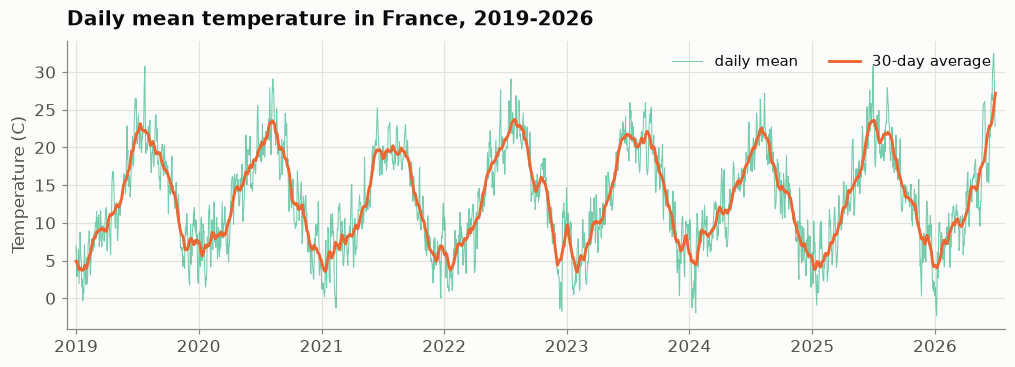

In [16]:
# Daily mean temperature through time (the weather driver itself)
tday = df["temperature_c"].resample("D").mean()
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(tday.index, tday.values, color=PALETTE["aqua"], lw=0.7, alpha=0.6, label="daily mean")
ax.plot(tday.index, tday.rolling(30, center=True, min_periods=10).mean().values,
        color=PALETTE["orange"], lw=1.9, label="30-day average")
ax.legend(loc="upper right", ncol=2)
titled(ax, "Daily mean temperature in France, 2019-2026", xlabel="", ylabel="Temperature (C)")
fig.savefig(FIG / "15_daily_temperature.png"); plt.show()

The daily mean temperature traces the **annual cycle** (cold winters near 0 C, warm summers ~20-30 C); the
30-day average makes the swing and the year-to-year differences clear. This weather driver - and its non-linear
link to load - is what we quantify next.

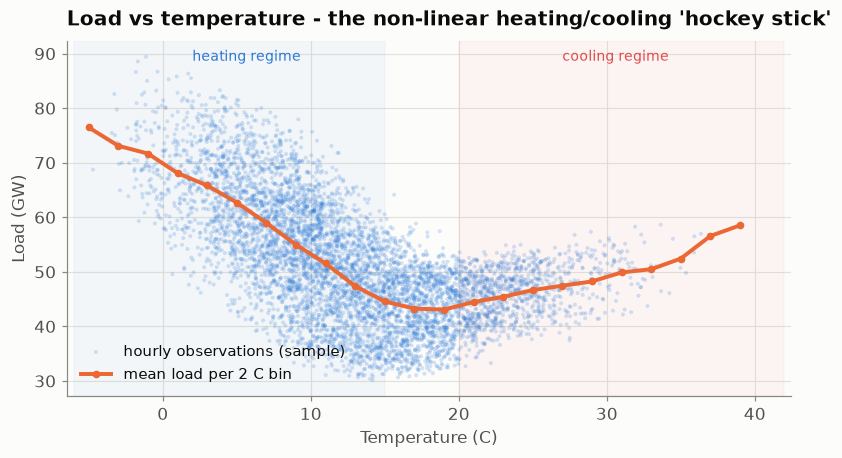

In [17]:
samp = df.sample(min(6000, len(df)), random_state=0)
bins = pd.cut(df["temperature_c"], np.arange(-6, 42, 2))
binned = df.groupby(bins, observed=True)["load_mw"].mean()
centers = [iv.mid for iv in binned.index]

fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.scatter(samp["temperature_c"], samp["load_mw"], s=7, alpha=0.20, color=PALETTE["blue"],
           edgecolors="none", label="hourly observations (sample)")
ax.plot(centers, binned.values, color=PALETTE["orange"], lw=2.6, marker="o", ms=4, label="mean load per 2 C bin")
ax.axvspan(-6, 15, color=PALETTE["blue"], alpha=0.04)
ax.axvspan(20, 42, color=PALETTE["red"], alpha=0.04)
ax.text(2, ax.get_ylim()[1]*0.96, "heating regime", color=PALETTE["blue"], fontsize=9)
ax.text(27, ax.get_ylim()[1]*0.96, "cooling regime", color=PALETTE["red"], fontsize=9)
ax.yaxis.set_major_formatter(gw_fmt)
ax.legend(loc="lower left")
titled(ax, "Load vs temperature - the non-linear heating/cooling 'hockey stick'",
       xlabel="Temperature (C)", ylabel="Load (GW)")
fig.savefig(FIG / "09_load_vs_temp.png")
plt.show()

In [18]:
# Correlation tests. Pearson = linear; Spearman = monotone. A single coefficient cannot capture a V-shape,
# so we also test physically-motivated degree-day transforms (heating below 15 C, cooling above 20 C).
pr, pp = stats.pearsonr(df["temperature_c"], df["load_mw"])
sr, sp = stats.spearmanr(df["temperature_c"], df["load_mw"])
hdd = np.maximum(15 - df["temperature_c"], 0)
cdd = np.maximum(df["temperature_c"] - 20, 0)
pr_h, _ = stats.pearsonr(hdd, df["load_mw"])
pr_c, _ = stats.pearsonr(cdd, df["load_mw"])

print("Raw temperature vs load:")
print(f"  Pearson  r = {pr:+.3f}   (linear,   p = {pp:.0e})")
print(f"  Spearman r = {sr:+.3f}   (monotone, p = {sp:.0e})")
print("\nAfter a physically-motivated degree-day transform:")
print(f"  Pearson(load, Heating-Degree base 15 C) = {pr_h:+.3f}   <- much stronger than raw temperature")
print(f"  Pearson(load, Cooling-Degree base 20 C) = {pr_c:+.3f}   <- weak: France is heating-dominated")
print("\nThe raw linear r understates the link because the relationship is V-shaped. The heating-degree")
print("transform recovers a strong signal - which is why Notebook 2 engineers degree-day features.")

Raw temperature vs load:
  Pearson  r = -0.605   (linear,   p = 0e+00)
  Spearman r = -0.631   (monotone, p = 0e+00)

After a physically-motivated degree-day transform:
  Pearson(load, Heating-Degree base 15 C) = +0.716   <- much stronger than raw temperature
  Pearson(load, Cooling-Degree base 20 C) = -0.124   <- weak: France is heating-dominated

The raw linear r understates the link because the relationship is V-shaped. The heating-degree
transform recovers a strong signal - which is why Notebook 2 engineers degree-day features.


## 6 - Auditing the RTE benchmark (framing question 1)
RTE's public day-ahead forecast is the bar to beat. We measure its error honestly and, crucially, find **where**
it fails - because that is where our model can add value.

In [19]:
df["rte_err"]     = df["load_mw"] - df["rte_forecast_d1_mw"]   # +ve => RTE under-forecast
df["rte_abs_err"] = df["rte_err"].abs()

def score(y, yhat):
    e = y - yhat
    return pd.Series({"MAE_MW": e.abs().mean(), "RMSE_MW": np.sqrt((e**2).mean()),
                      "MAPE_%": (e.abs() / y).mean() * 100, "Bias_MW": e.mean()})

rte_scores = score(df["load_mw"], df["rte_forecast_d1_mw"])
print("RTE day-ahead forecast error (full history):")
print(rte_scores.to_string())
print(f"\nThat MAPE of {rte_scores['MAPE_%']:.2f}% is a strong benchmark - beating it HONESTLY is the real challenge.")

RTE day-ahead forecast error (full history):
MAE_MW    1,143.518
RMSE_MW   1,490.983
MAPE_%        2.251
Bias_MW     671.466

That MAPE of 2.25% is a strong benchmark - beating it HONESTLY is the real challenge.


In [ ]:
# Is the +Bias (RTE under-forecast) statistically real, or noise?
t, p = stats.ttest_1samp(df["rte_err"].dropna(), 0)
ci = stats.t.interval(0.95, len(df["rte_err"].dropna()) - 1,
                      loc=df["rte_err"].mean(), scale=stats.sem(df["rte_err"].dropna()))
print(f"One-sample t-test on mean RTE error (H0: bias = 0):  t = {t:,.1f},  p = {p:.1e}")
print(f"Mean error = {df['rte_err'].mean():+,.0f} MW,  95% CI = [{ci[0]:+,.0f}, {ci[1]:+,.0f}] MW")
print("\n-> RTE systematically UNDER-forecasts by a small but highly significant margin: a bias our model can remove.")

# Is there exploitable autocorrelation left in RTE's residuals?
lb_r = acorr_ljungbox(df["rte_err"].dropna(), lags=[24, 168], return_df=True)
print("\nLjung-Box on RTE residuals (H0: no autocorrelation):")
print(lb_r.to_string())

One-sample t-test on mean RTE error (H0: bias = 0):  t = 129.3,  p = 0.0e+00
Mean error = +671 MW,  95% CI = [+661, +682] MW

-> RTE systematically UNDER-forecasts by a small but highly significant margin: a bias our model can remove.



Ljung-Box on RTE residuals (H0: no autocorrelation):
        lb_stat  lb_pvalue
24  277,571.276      0.000
168 622,889.862      0.000


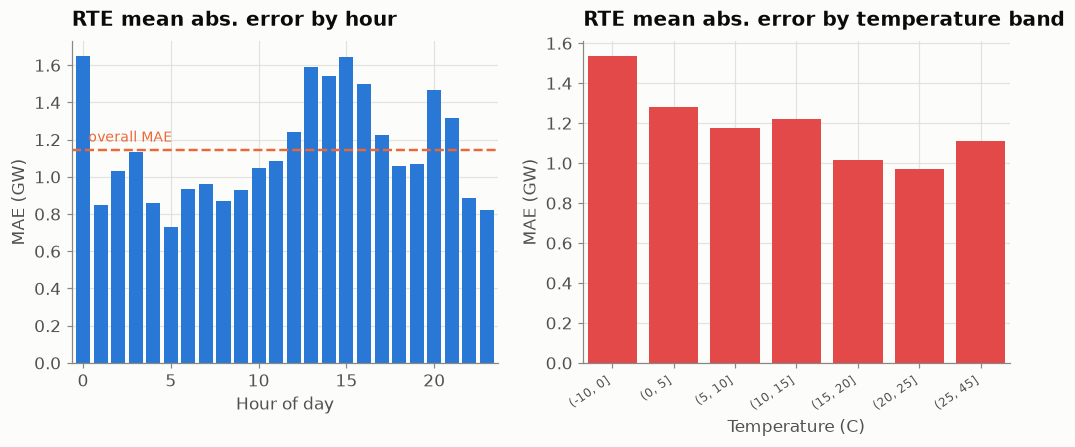

In [21]:
# WHERE does RTE fail? By hour of day and by temperature band.
by_hour = df.groupby("hour")["rte_abs_err"].mean()
tband = pd.cut(df["temperature_c"], [-10, 0, 5, 10, 15, 20, 25, 45])
by_temp = df.groupby(tband, observed=True)["rte_abs_err"].mean()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].bar(by_hour.index, by_hour.values, color=PALETTE["blue"], width=0.8)
axes[0].axhline(rte_scores["MAE_MW"], color=PALETTE["orange"], lw=1.6, ls="--")
axes[0].text(0.3, rte_scores["MAE_MW"]*1.04, "overall MAE", color=PALETTE["orange"], fontsize=9)
axes[0].yaxis.set_major_formatter(gw1_fmt)
titled(axes[0], "RTE mean abs. error by hour", xlabel="Hour of day", ylabel="MAE (GW)")

axes[1].bar(range(len(by_temp)), by_temp.values, color=PALETTE["red"], width=0.8)
axes[1].set_xticks(range(len(by_temp)))
axes[1].set_xticklabels([str(iv) for iv in by_temp.index], rotation=35, ha="right", fontsize=8)
axes[1].yaxis.set_major_formatter(gw1_fmt)
titled(axes[1], "RTE mean abs. error by temperature band", xlabel="Temperature (C)", ylabel="MAE (GW)")
fig.savefig(FIG / "10_rte_error_breakdown.png")
plt.show()

**Where RTE struggles - our opportunity.** Errors are largest in the **evening peak hours** and at the
**temperature extremes** (cold snaps especially). RTE also carries a small but statistically significant
**under-forecast bias**, and its residuals remain autocorrelated at 24h/168h (Ljung-Box p ~ 0) - meaning there is
**structure left on the table**. A model that removes the bias and sharpens cold-evening predictions is exactly
how we can beat this benchmark where it matters most financially.

## 7 - Simple baseline models (the floor to beat)
Before anything sophisticated, we establish **trivial seasonal-naive baselines** - they cost nothing and answer a
blunt question: how far can you get by simply *repeating the past*? Any real model, and RTE itself, must comfortably
beat these to earn its place. We use three:
- **Naive-daily (D-1)**: the load at the same hour **yesterday** (lag 24h).
- **Naive-weekly (D-7)**: the load at the same hour, **same weekday last week** (lag 168h).
- **Seasonal-cascade**: the same hour **~1 year ago** (52 weeks, keeps the weekday); where that is unavailable it
  falls back to **last week -> last day -> last hour**, so it always returns a value.

In [22]:
load = df["load_mw"]

# Three naive predictors (retrospective lags; each uses only earlier observations)
pred = pd.DataFrame(index=df.index)
pred["Naive-daily (D-1)"]  = load.shift(24)
pred["Naive-weekly (D-7)"] = load.shift(168)
cascade = load.shift(24 * 364)                               # same hour, same weekday, ~1 year ago
cascade = cascade.fillna(load.shift(168)).fillna(load.shift(24)).fillna(load.shift(1))
pred["Seasonal-cascade (1y->1w->1d)"] = cascade
pred["RTE forecast"] = df["rte_forecast_d1_mw"]

# Score from 2020 onward, so the 1-year lag is genuinely available for every predictor (reuse score() from above)
ev = pred.join(load.rename("y")).loc["2020-01-01":].dropna()
scores = pd.DataFrame({c: score(ev["y"], ev[c]) for c in pred.columns}).T.sort_values("MAE_MW")
scores["MAE_vs_RTE_x"] = (scores["MAE_MW"] / scores.loc["RTE forecast", "MAE_MW"]).round(2)
scores.round(1)

,MAE_MW,RMSE_MW,MAPE_%,Bias_MW,MAE_vs_RTE_x
RTE forecast,"1,191.600","1,544.100",2.400,739.700,1.000
Naive-daily (D-1),"2,606.000","3,805.200",5.200,-7.600,2.200
Naive-weekly (D-7),"3,521.100","5,160.700",6.500,-30.000,3.000
Seasonal-cascade (1y->1w->1d),"4,130.700","5,829.300",7.800,-459.200,3.500


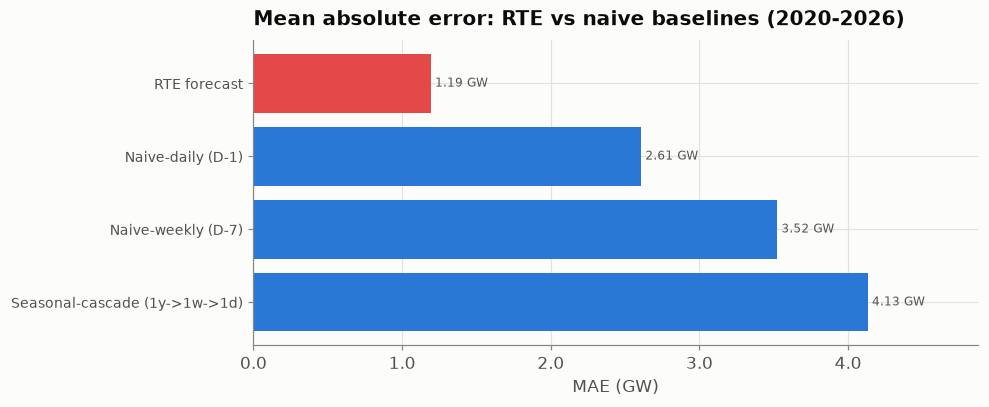

In [23]:
fig, ax = plt.subplots(figsize=(8.5, 3.6))
colors = [PALETTE["red"] if n == "RTE forecast" else PALETTE["blue"] for n in scores.index]
ax.barh(range(len(scores)), scores["MAE_MW"].values, color=colors)
ax.set_yticks(range(len(scores))); ax.set_yticklabels(scores.index, fontsize=9)
for i, v in enumerate(scores["MAE_MW"].values):
    ax.text(v + 30, i, f"{v/1000:,.2f} GW", va="center", fontsize=8, color=PALETTE["ink2"])
ax.xaxis.set_major_formatter(gw1_fmt); ax.set_xlim(0, scores["MAE_MW"].max() * 1.18)
ax.invert_yaxis()   # best (lowest MAE) on top
titled(ax, "Mean absolute error: RTE vs naive baselines (2020-2026)", xlabel="MAE (GW)")
fig.savefig(FIG / "12_baselines.png")
plt.show()

**Reading the floor.** RTE's error is **2-3.5x smaller** than every naive baseline - exactly as it should be,
since RTE embeds weather forecasts that a pure lag cannot. Among the naive rules the pattern is striking and
instructive: the **shorter the lag, the better** - daily (D-1, ~2.6 GW) beats weekly (D-7, ~3.5 GW) beats the
yearly-cascade (~4.1 GW). Day-ahead load is driven mostly by weather and overall level, which persist strongly from
one day to the next but have *completely changed* a week - let alone a year - later. So the "smarter-looking"
long-season baselines are actually **worse** here; raw day-to-day persistence is the toughest naive rule to beat.
This sets the bar for Notebook 02: our models must crush even the best naive rule **and** edge past RTE (~1.2 GW).

*Day-ahead caveat.* These are retrospective lag predictors. Operationally, at 12:00 on day D the **daily** lag
would reference day D (not yet fully observed); the **weekly** and **yearly** lags are safely available. Notebook 02
enforces the strict cutoff in its backtest - here the baselines are illustrative reference points.

### Forecasts vs actual load
A single MAE number hides *how* a forecast behaves. These plots show it directly: how tightly each forecast tracks
real demand across a typical **winter** and **summer** week, and how the whole cloud of predictions lines up
against reality.

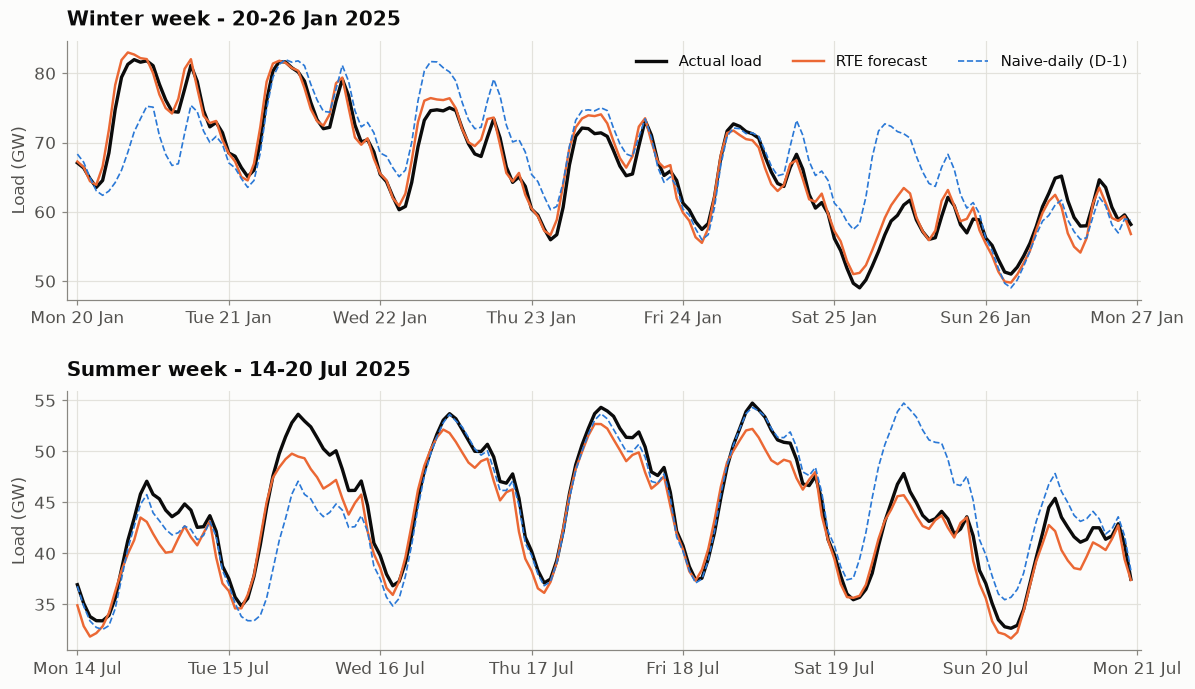

In [24]:
naive_daily = df["load_mw"].shift(24)   # best naive baseline, for reference

weeks = [("2025-01-20", "2025-01-26", "Winter week - 20-26 Jan 2025"),
         ("2025-07-14", "2025-07-20", "Summer week - 14-20 Jul 2025")]
fig, axes = plt.subplots(2, 1, figsize=(11, 6.4))
for ax, (a, b, ttl) in zip(axes, weeks):
    w = df.loc[a:b]
    ax.plot(w.index, w["load_mw"],              color=PALETTE["ink"],    lw=2.2, label="Actual load")
    ax.plot(w.index, w["rte_forecast_d1_mw"],   color=PALETTE["orange"], lw=1.6, label="RTE forecast")
    ax.plot(w.index, naive_daily.loc[a:b],      color=PALETTE["blue"],   lw=1.1, ls="--", label="Naive-daily (D-1)")
    ax.yaxis.set_major_formatter(gw_fmt)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%a %d %b"))
    titled(ax, ttl, ylabel="Load (GW)")
axes[0].legend(loc="upper right", ncol=3)
fig.tight_layout(h_pad=2.0)   # keep the lower panel's title clear of the upper panel's axis labels
fig.savefig(FIG / "13_forecast_vs_actual_weeks.png")
plt.show()

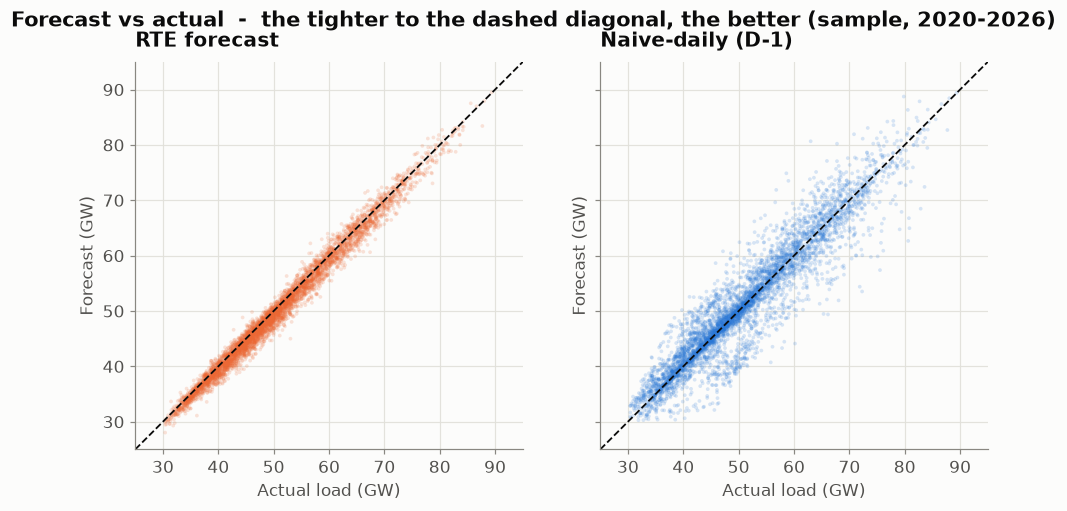

In [25]:
# Predicted vs actual over 2020-2026 (points on the diagonal = perfect)
base = df.loc["2020-01-01":, ["load_mw", "rte_forecast_d1_mw"]].copy()
base["naive_daily"] = naive_daily.loc["2020-01-01":]
samp = base.dropna().sample(5000, random_state=0)

lo, hi = 25, 95  # GW
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6), sharex=True, sharey=True)
for ax, (col, name, c) in zip(axes, [("rte_forecast_d1_mw", "RTE forecast", PALETTE["orange"]),
                                     ("naive_daily", "Naive-daily (D-1)", PALETTE["blue"])]):
    ax.scatter(samp["load_mw"] / 1000, samp[col] / 1000, s=6, alpha=0.18, color=c, edgecolors="none")
    ax.plot([lo, hi], [lo, hi], color=PALETTE["ink"], lw=1.2, ls="--")
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_aspect("equal")
    titled(ax, name, xlabel="Actual load (GW)", ylabel="Forecast (GW)")
fig.suptitle("Forecast vs actual  -  the tighter to the dashed diagonal, the better (sample, 2020-2026)",
             x=0.012, ha="left")
fig.savefig(FIG / "14_forecast_vs_actual_scatter.png")
plt.show()

**What the eye confirms.** RTE (orange) hugs the actual demand almost everywhere - it tracks the daily
double-peak and the evening maximum closely, and its scatter clings to the perfect-fit diagonal. The naive-daily
baseline (blue) shadows the overall shape but lags and overshoots whenever the level shifts (a warm-up, a cold
snap, a weekend), and its scatter is a visibly wider cloud. This is the picture behind the MAE gap: RTE is a
genuinely strong forecast, so beating it will take real weather + calendar modelling, not just repeating the past.

## 8 - The evaluation split
All models in Notebooks 2 & 3 are trained, tuned and judged on the **same chronological split** (assigned in
Notebook 00) - never shuffled, so no future information leaks into the past. Here we read it and visualise it.

In [26]:
g = df.reset_index().groupby("split")
span = pd.DataFrame({"from": g["datetime_utc"].min().dt.date,
                     "to":   g["datetime_utc"].max().dt.date,
                     "hours": g.size()})
span["years"] = (span["hours"] / 8760).round(2)
span = span.reindex(["train", "val", "test"])
print(span.to_string())

             from          to  hours  years
split                                      
train  2019-01-01  2023-12-31  43823  5.000
val    2023-12-31  2024-12-31   8784  1.000
test   2024-12-31  2026-06-30  13105  1.500


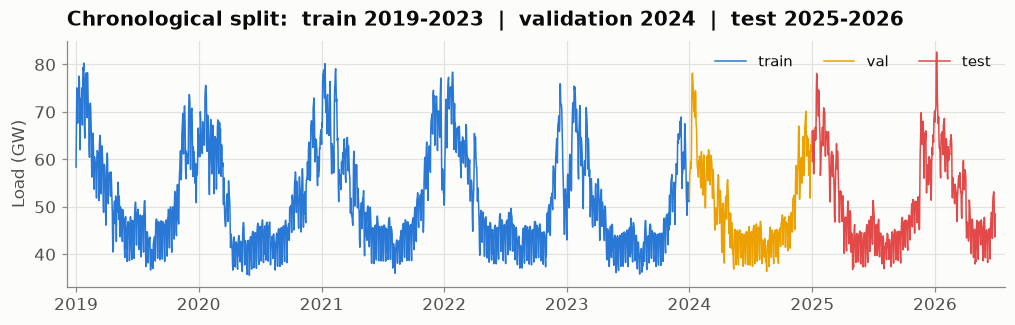

In [27]:
# Timeline coloured by split (daily mean)
split_daily = df["split"].resample("D").first()
fig, ax = plt.subplots(figsize=(11, 2.9))
cmap = {"train": PALETTE["blue"], "val": PALETTE["yellow"], "test": PALETTE["red"]}
for name, c in cmap.items():
    mask = split_daily.reindex(daily.index) == name
    ax.plot(daily.index[mask.values], daily.values[mask.values], color=c, lw=1.0, label=name)
ax.yaxis.set_major_formatter(gw_fmt)
ax.legend(loc="upper right", ncol=3)
titled(ax, "Chronological split:  train 2019-2023  |  validation 2024  |  test 2025-2026",
       xlabel="", ylabel="Load (GW)")
fig.savefig(FIG / "11_split_timeline.png")
plt.show()

**Why this split.** Train (2019-2023) covers COVID and the 2022 energy crisis, so the models see varied
regimes. Validation (2024) is for model selection and hyper-parameters. Test (2025 - 2026-06) is a **locked box**
opened only for the final, honest scorecard in Notebook 3. Chronological order mirrors real operations: we always
predict the future from the past.

## 9 - Summary of findings

**Structure - rich and learnable.**
- Strong **daily (24h)** and **weekly (168h)** seasonality plus a **winter annual peak**; Ljung-Box p ~ 0 at all three.
- KPSS + ADF agree the raw series is non-stationary but becomes stationary after **seasonal (lag-24) differencing** -> SARIMA orders justified.
- Temperature is the dominant driver via a **non-linear V-shape**: raw Pearson r = -0.60, but a **heating-degree
  transform lifts it to +0.72** -> motivates degree-day features.

**The benchmark - strong but beatable where it counts.**
- RTE day-ahead: **MAE ~ 1.14 GW, RMSE ~ 1.49 GW, MAPE ~ 2.25%**.
- RTE beats trivial seasonal-naive baselines by **2-3.5x** (best naive = day-to-day persistence, ~2.6 GW MAE) -> a serious bar, not a strawman.
- A small but **statistically significant under-forecast bias** (+0.67 GW, t-test p ~ 0) and **autocorrelated residuals** -> exploitable.
- Errors concentrate in **evening peaks** and **temperature extremes** - the financially expensive hours.

**Evaluation ready.**
- Fixed chronological split (train 2019-2023 / val 2024 / test 2025-2026), inherited from Notebook 00.
- Data cleaning and regional preparation live in **Notebook 00**.

**Next - Notebook 2:** engineer cut-off-respecting features and benchmark a ladder of models
(seasonal-naive -> Holt-Winters -> SARIMA/SARIMAX -> XGBoost/LightGBM) against RTE under the day-ahead protocol.